In [1]:
import os
import cv2
import json
from tqdm import tqdm
from ultralytics import YOLO
from collections import Counter

In [2]:
DATA_ROOT = r"Sample (1)\Sample\01.원천데이터"

CF2_DIR = "cf2"

os.makedirs(
    CF2_DIR,
    exist_ok=True
)

FRAME_INTERVAL = 5

CONF_THRESHOLD = 0.15

In [3]:
model = YOLO("yolov8s.pt")

print("loaded")

loaded


In [4]:
TARGET_DIRS = [

    "이륜 이동수단 인도 주행",

    "이륜 이동수단 헬멧 미착용"
]

video_files = []

for target in TARGET_DIRS:

    root_dir = os.path.join(
        DATA_ROOT,
        target
    )

    for root, dirs, files in os.walk(root_dir):

        for file in files:

            if file.endswith(".mp4"):

                video_files.append(
                    os.path.join(
                        root,
                        file
                    )
                )

print(
    "videos:",
    len(video_files)
)

for v in video_files:
    print(os.path.basename(v))

videos: 10
ms_e3500_c1.mp4
ms_e3500_c2.mp4
bs_e4387_c1.mp4
bs_e4387_c2.mp4
es_e3768_c1.mp4
es_e3768_c2.mp4
md_e2122_c1.mp4
md_e2122_c2.mp4
mp_e2730_c1.mp4
mp_e2730_c2.mp4


In [5]:
def detect_video(video_path):

    cap = cv2.VideoCapture(video_path)

    frame_id = 0

    frames = []

    summary = Counter()

    while True:

        ret, frame = cap.read()

        if not ret:
            break

        if frame_id % FRAME_INTERVAL != 0:

            frame_id += 1
            continue

        result = model(
            frame,
            verbose=False,
            conf=CONF_THRESHOLD
        )[0]

        objects = []

        classes = []

        for box in result.boxes:

            cls_id = int(box.cls[0])

            cls_name = (
                model.names[cls_id]
            )

            conf = float(
                box.conf[0]
            )

            bbox = (
                box.xyxy[0]
                .cpu()
                .numpy()
                .astype(int)
                .tolist()
            )

            # 중요
            if cls_name not in [

                "person",

                "bicycle",

                "motorcycle"

            ]:
                continue

            summary[cls_name] += 1

            classes.append(
                cls_name
            )

            objects.append({

                "class":
                    cls_name,

                "confidence":
                    round(conf,4),

                "bbox":
                    bbox
            })

        frames.append({

            "frame_id":
                frame_id,

            "object_count":
                len(objects),

            "classes":
                classes,

            "objects":
                objects
        })

        frame_id += 1

    cap.release()

    return frames, dict(summary)

In [6]:
for video_path in tqdm(video_files):

    video_name = os.path.basename(
        video_path
    )

    print(
        f"\nProcessing {video_name}"
    )

    frames, summary = detect_video(
        video_path
    )

    result_json = {

        "video_name":
            video_name,

        "summary":
            summary,

        "frames":
            frames
    }

    save_path = os.path.join(

        CF2_DIR,

        video_name.replace(
            ".mp4",
            ".json"
        )
    )

    with open(
        save_path,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            result_json,
            f,
            ensure_ascii=False,
            indent=4
        )

    print(summary)

  0%|                                                                                           | 0/10 [00:00<?, ?it/s]


Processing ms_e3500_c1.mp4


 10%|████████▎                                                                          | 1/10 [00:19<02:54, 19.43s/it]

{'person': 4}

Processing ms_e3500_c2.mp4


 20%|████████████████▌                                                                  | 2/10 [00:36<02:26, 18.28s/it]

...

{'person': 526, 'motorcycle': 16, 'bicycle': 1}

Processing mp_e2730_c1.mp4


 90%|██████████████████████████████████████████████████████████████████████████▋        | 9/10 [02:59<00:21, 21.50s/it]

{'person': 105, 'motorcycle': 77, 'bicycle': 1}

Processing mp_e2730_c2.mp4


100%|██████████████████████████████████████████████████████████████████████████████████| 10/10 [03:20<00:00, 20.06s/it]

{'bicycle': 11, 'person': 172, 'motorcycle': 74}


In [7]:
import glob

json_files = glob.glob(
    "cf2/*.json"
)

print(
    "json count:",
    len(json_files)
)

for path in json_files:

    with open(
        path,
        encoding="utf-8"
    ) as f:

        data = json.load(f)

    print(
        "\n",
        os.path.basename(path)
    )

    print(
        data["summary"]
    )

json count: 10

 bs_e4387_c1.json
{'bicycle': 22, 'person': 79, 'motorcycle': 2}

 bs_e4387_c2.json
{'person': 69, 'motorcycle': 1, 'bicycle': 3}

 es_e3768_c1.json
{'person': 149, 'motorcycle': 27, 'bicycle': 15}

 es_e3768_c2.json
{'person': 455, 'bicycle': 130, 'motorcycle': 128}

 md_e2122_c1.json
{'person': 775, 'bicycle': 18, 'motorcycle': 264}

 md_e2122_c2.json
{'person': 526, 'motorcycle': 16, 'bicycle': 1}

 mp_e2730_c1.json
{'person': 105, 'motorcycle': 77, 'bicycle': 1}

 mp_e2730_c2.json
{'bicycle': 11, 'person': 172, 'motorcycle': 74}

 ms_e3500_c1.json
{'person': 4}

 ms_e3500_c2.json
{'person': 31, 'motorcycle': 3, 'bicycle': 1}


In [8]:
import math

In [9]:
def center(box):

    x1,y1,x2,y2 = box

    return (
        (x1+x2)/2,
        (y1+y2)/2
    )


def distance(c1,c2):

    return math.sqrt(
        (c1[0]-c2[0])**2 +
        (c1[1]-c2[1])**2
    )

In [10]:
def riding_pairs(frame):

    persons = []
    vehicles = []

    for obj in frame["objects"]:

        if obj["class"] == "person":

            persons.append(obj)

        elif obj["class"] in [
            "motorcycle",
            "bicycle"
        ]:

            vehicles.append(obj)

    pairs = []

    for p in persons:

        pc = center(p["bbox"])

        for v in vehicles:

            vc = center(v["bbox"])

            d = distance(pc, vc)

            if d < 180:

                pairs.append(
                    {
                        "person":p,
                        "vehicle":v,
                        "distance":round(d,1)
                    }
                )

    return pairs

In [11]:
def analyze_riding(data):

    riding_frames = 0
    vehicle_frames = 0

    total_pairs = 0

    streak = 0
    max_streak = 0

    for frame in data["frames"]:

        pairs = riding_pairs(frame)

        has_vehicle = False

        for obj in frame["objects"]:

            if obj["class"] in [
                "motorcycle",
                "bicycle"
            ]:

                has_vehicle = True
                break

        if has_vehicle:

            vehicle_frames += 1

        if len(pairs) > 0:

            riding_frames += 1
            total_pairs += len(pairs)

            streak += 1
            max_streak = max(
                max_streak,
                streak
            )

        else:

            streak = 0

    return {

        "vehicle_frames":vehicle_frames,

        "riding_frames":riding_frames,

        "riding_ratio":
            round(
                riding_frames /
                max(vehicle_frames,1),
                3
            ),

        "total_pairs":total_pairs,

        "max_riding_streak":
            max_streak
    }

In [12]:
import glob
import json
import os

In [13]:
json_files = glob.glob(
    "CF2/*.json"
)

for file in sorted(json_files):

    with open(
        file,
        encoding="utf-8"
    ) as f:

        data = json.load(f)

    result = analyze_riding(data)

    print("\n----------------")
    print(
        os.path.basename(file)
    )

    print(result)


----------------
bs_e4387_c1.json
{'vehicle_frames': 20, 'riding_frames': 17, 'riding_ratio': 0.85, 'total_pairs': 23, 'max_riding_streak': 10}

----------------
bs_e4387_c2.json
{'vehicle_frames': 3, 'riding_frames': 2, 'riding_ratio': 0.667, 'total_pairs': 3, 'max_riding_streak': 1}

----------------
es_e3768_c1.json
{'vehicle_frames': 29, 'riding_frames': 14, 'riding_ratio': 0.483, 'total_pairs': 24, 'max_riding_streak': 3}

----------------
es_e3768_c2.json
{'vehicle_frames': 134, 'riding_frames': 113, 'riding_ratio': 0.843, 'total_pairs': 335, 'max_riding_streak': 34}

----------------
md_e2122_c1.json
{'vehicle_frames': 155, 'riding_frames': 97, 'riding_ratio': 0.626, 'total_pairs': 291, 'max_riding_streak': 21}

----------------
md_e2122_c2.json
{'vehicle_frames': 11, 'riding_frames': 2, 'riding_ratio': 0.182, 'total_pairs': 3, 'max_riding_streak': 1}

----------------
mp_e2730_c1.json
{'vehicle_frames': 64, 'riding_frames': 62, 'riding_ratio': 0.969, 'total_pairs': 79, 'max_ri

In [14]:
def bbox_center(box):

    x1,y1,x2,y2 = box

    return (
        (x1+x2)/2,
        (y1+y2)/2
    )

In [15]:
def dist(a,b):

    return math.sqrt(
        (a[0]-b[0])**2 +
        (a[1]-b[1])**2
    )

In [16]:
def collect_distances(data):

    distances = []

    for frame in data["frames"]:

        persons = []
        vehicles = []

        for obj in frame["objects"]:

            if obj["class"]=="person":
                persons.append(obj)

            elif obj["class"] in [
                "motorcycle",
                "bicycle"
            ]:
                vehicles.append(obj)

        for p in persons:

            pc = bbox_center(
                p["bbox"]
            )

            for v in vehicles:

                vc = bbox_center(
                    v["bbox"]
                )

                distances.append(
                    dist(pc,vc)
                )

    return distances

In [17]:
for file in json_files:

    with open(file,encoding="utf-8") as f:
        data=json.load(f)

    d=collect_distances(data)

    if len(d)==0:
        continue

    print()
    print(os.path.basename(file))
    print("avg",round(sum(d)/len(d),1))
    print("min",round(min(d),1))


bs_e4387_c1.json
avg 61.8
min 23.3

bs_e4387_c2.json
avg 72.4
min 53.0

es_e3768_c1.json
avg 314.3
min 1.1

es_e3768_c2.json
avg 297.5
min 0.7

md_e2122_c1.json
avg 281.9
min 0.5

md_e2122_c2.json
avg 421.3
min 76.0

mp_e2730_c1.json
avg 126.0
min 3.8

mp_e2730_c2.json
avg 230.0
min 3.2

ms_e3500_c2.json
avg 601.7
min 569.1


In [18]:
from collections import Counter
import math

In [19]:
def get_feature(data):

    person_count = 0
    bicycle_count = 0
    motorcycle_count = 0

    vehicle_frames = 0
    riding_frames = 0

    total_pairs = 0

    streak = 0
    max_streak = 0

    distances = []

    for frame in data["frames"]:

        persons = []
        vehicles = []

        for obj in frame["objects"]:

            cls = obj["class"]

            if cls == "person":
                person_count += 1
                persons.append(obj)

            elif cls == "bicycle":
                bicycle_count += 1
                vehicles.append(obj)

            elif cls == "motorcycle":
                motorcycle_count += 1
                vehicles.append(obj)

        if len(vehicles) > 0:
            vehicle_frames += 1

        frame_pairs = 0

        for p in persons:

            px1,py1,px2,py2 = p["bbox"]

            pcx = (px1+px2)/2
            pcy = (py1+py2)/2

            for v in vehicles:

                vx1,vy1,vx2,vy2 = v["bbox"]

                vcx = (vx1+vx2)/2
                vcy = (vy1+vy2)/2

                d = math.sqrt(
                    (pcx-vcx)**2 +
                    (pcy-vcy)**2
                )

                distances.append(d)

                if d < 180:

                    frame_pairs += 1

        total_pairs += frame_pairs

        if frame_pairs > 0:

            riding_frames += 1

            streak += 1

            max_streak = max(
                max_streak,
                streak
            )

        else:

            streak = 0

    two_wheel = (
        bicycle_count +
        motorcycle_count
    )

    avg_distance = (
        sum(distances)/len(distances)
        if len(distances) > 0
        else 9999
    )

    return {

        "person": person_count,

        "bicycle": bicycle_count,

        "motorcycle": motorcycle_count,

        "two_wheel": two_wheel,

        "bicycle_ratio":
            round(
                bicycle_count /
                max(two_wheel,1),
                3
            ),

        "motorcycle_ratio":
            round(
                motorcycle_count /
                max(two_wheel,1),
                3
            ),

        "vehicle_frames":
            vehicle_frames,

        "riding_frames":
            riding_frames,

        "riding_ratio":
            round(
                riding_frames /
                max(vehicle_frames,1),
                3
            ),

        "total_pairs":
            total_pairs,

        "max_riding_streak":
            max_streak,

        "avg_distance":
            round(avg_distance,1)
    }

In [20]:
import os

FEATURE_DIR = "CF2_FEATURE"

os.makedirs(
    FEATURE_DIR,
    exist_ok=True
)

In [21]:
import glob
import json

In [22]:
json_files = glob.glob(
    "CF2/*.json"
)

for file in json_files:

    with open(
        file,
        encoding="utf-8"
    ) as f:

        data = json.load(f)

    feature = get_feature(data)

    save_path = os.path.join(

        FEATURE_DIR,

        os.path.basename(file)
    )

    with open(
        save_path,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            feature,
            f,
            ensure_ascii=False,
            indent=4
        )

print("done")

done


In [23]:
for file in sorted(
    glob.glob(
        "CF2_FEATURE/*.json"
    )
):

    with open(
        file,
        encoding="utf-8"
    ) as f:

        feat = json.load(f)

    print()
    print(os.path.basename(file))
    print(feat)


bs_e4387_c1.json
{'person': 79, 'bicycle': 22, 'motorcycle': 2, 'two_wheel': 24, 'bicycle_ratio': 0.917, 'motorcycle_ratio': 0.083, 'vehicle_frames': 20, 'riding_frames': 17, 'riding_ratio': 0.85, 'total_pairs': 23, 'max_riding_streak': 10, 'avg_distance': 61.8}

bs_e4387_c2.json
{'person': 69, 'bicycle': 3, 'motorcycle': 1, 'two_wheel': 4, 'bicycle_ratio': 0.75, 'motorcycle_ratio': 0.25, 'vehicle_frames': 3, 'riding_frames': 2, 'riding_ratio': 0.667, 'total_pairs': 3, 'max_riding_streak': 1, 'avg_distance': 72.4}

es_e3768_c1.json
{'person': 149, 'bicycle': 15, 'motorcycle': 27, 'two_wheel': 42, 'bicycle_ratio': 0.357, 'motorcycle_ratio': 0.643, 'vehicle_frames': 29, 'riding_frames': 14, 'riding_ratio': 0.483, 'total_pairs': 24, 'max_riding_streak': 3, 'avg_distance': 314.3}

es_e3768_c2.json
{'person': 455, 'bicycle': 130, 'motorcycle': 128, 'two_wheel': 258, 'bicycle_ratio': 0.504, 'motorcycle_ratio': 0.496, 'vehicle_frames': 134, 'riding_frames': 113, 'riding_ratio': 0.843, 'total

In [24]:
#상황 분류 규칙 만들기

In [25]:
def classify_scene(feature):

    if feature["two_wheel"] == 0:
        return "NO_TWO_WHEEL"

    if feature["riding_ratio"] > 0.8:

        if feature["motorcycle_ratio"] > 0.7:
            return "MOTORCYCLE_RIDING"

        if feature["bicycle_ratio"] > 0.7:
            return "BICYCLE_RIDING"

        return "RIDING"

    if feature["riding_ratio"] > 0.3:
        return "PARTIAL_RIDING"

    if feature["person"] > feature["two_wheel"] * 4:
        return "CROWD_AREA"

    return "PARKING_OR_WAITING"

In [29]:
print(data.keys())

dict_keys(['video_name', 'summary', 'frames'])


In [30]:
print(data["frames"][0].keys())

dict_keys(['frame_id', 'object_count', 'classes', 'objects'])


In [31]:
print(data["summary"])

{'bicycle': 22, 'person': 79, 'motorcycle': 2}


In [32]:
print(data["frames"][10]["objects"])

[]


In [33]:
for frame in data["frames"]:
    if len(frame["objects"]) > 0:
        print(frame["objects"])
        break

[{'class': 'bicycle', 'confidence': 0.662, 'bbox': [1209, 931, 1303, 1078]}]


In [34]:
import os
import json
from math import sqrt

In [35]:
def center_from_bbox(bbox):

    x1, y1, x2, y2 = bbox

    return (
        (x1 + x2) / 2,
        (y1 + y2) / 2
    )


def distance(p1, p2):

    return sqrt(
        (p1[0]-p2[0])**2 +
        (p1[1]-p2[1])**2
    )

In [36]:
def analyze_video(data):

    vehicle_frames = 0
    riding_frames = 0

    total_pairs = 0

    current_streak = 0
    max_streak = 0

    distances = []

    for frame in data["frames"]:

        persons = []
        vehicles = []

        for obj in frame["objects"]:

            center = center_from_bbox(
                obj["bbox"]
            )

            if obj["class"] == "person":
                persons.append(center)

            elif obj["class"] in [
                "bicycle",
                "motorcycle"
            ]:
                vehicles.append(center)

        if len(vehicles) > 0:
            vehicle_frames += 1

        riding = False

        for p in persons:
            for v in vehicles:

                d = distance(p, v)

                distances.append(d)

                if d < 150:

                    riding = True
                    total_pairs += 1

        if riding:

            riding_frames += 1

            current_streak += 1

            if current_streak > max_streak:
                max_streak = current_streak

        else:

            current_streak = 0

    riding_ratio = 0

    if vehicle_frames > 0:

        riding_ratio = (
            riding_frames /
            vehicle_frames
        )

    avg_distance = 9999

    if len(distances) > 0:

        avg_distance = round(
            sum(distances) /
            len(distances),
            1
        )

    return {

        "vehicle_frames": vehicle_frames,

        "riding_frames": riding_frames,

        "riding_ratio": round(
            riding_ratio,
            3
        ),

        "total_pairs": total_pairs,

        "max_riding_streak": max_streak,

        "avg_distance": avg_distance
    }

In [37]:
def classify_scene(feature):

    if feature["vehicle_frames"] == 0:
        return "NO_TWO_WHEEL"

    if (
        feature["riding_ratio"] > 0.8
        and
        feature["max_riding_streak"] > 10
    ):
        return "RIDING"

    if feature["riding_ratio"] > 0.3:
        return "PARTIAL_RIDING"

    return "WAITING_OR_PARKING"

In [47]:
import os
import json

CF2_DIR = "cf2"
OUTPUT_DIR = "cfend2"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# 폴더 체크
if not os.path.exists(CF2_DIR):
    raise FileNotFoundError(f"폴더 없음: {CF2_DIR}")

for file_name in os.listdir(CF2_DIR):

    if not file_name.endswith(".json"):
        continue

    file_path = os.path.join(CF2_DIR, file_name)

    try:
        with open(file_path, encoding="utf-8") as f:
            data = json.load(f)

        feature = analyze_video(data)
        label = classify_scene(feature)

        result = {
            "scene": label,
            "feature": feature
        }

        # 🔥 영상별 JSON 저장
        save_path = os.path.join(
            OUTPUT_DIR,
            file_name  # 동일 이름으로 저장
        )

        with open(save_path, "w", encoding="utf-8") as f:
            json.dump(result, f, ensure_ascii=False, indent=2)

        print(file_name)
        print(label)
        print(feature)
        print("saved ->", save_path)
        print()

    except Exception as e:
        print(f"[ERROR] {file_name}: {e}")

bs_e4387_c1.json
PARTIAL_RIDING
{'vehicle_frames': 20, 'riding_frames': 17, 'riding_ratio': 0.85, 'total_pairs': 23, 'max_riding_streak': 10, 'avg_distance': 61.8}
saved -> cfend2\bs_e4387_c1.json

bs_e4387_c2.json
PARTIAL_RIDING
{'vehicle_frames': 3, 'riding_frames': 2, 'riding_ratio': 0.667, 'total_pairs': 3, 'max_riding_streak': 1, 'avg_distance': 72.4}
saved -> cfend2\bs_e4387_c2.json

es_e3768_c1.json
PARTIAL_RIDING
{'vehicle_frames': 29, 'riding_frames': 14, 'riding_ratio': 0.483, 'total_pairs': 24, 'max_riding_streak': 3, 'avg_distance': 314.3}
saved -> cfend2\es_e3768_c1.json

es_e3768_c2.json
PARTIAL_RIDING
{'vehicle_frames': 134, 'riding_frames': 103, 'riding_ratio': 0.769, 'total_pairs': 224, 'max_riding_streak': 32, 'avg_distance': 297.5}
saved -> cfend2\es_e3768_c2.json

md_e2122_c1.json
PARTIAL_RIDING
{'vehicle_frames': 155, 'riding_frames': 81, 'riding_ratio': 0.523, 'total_pairs': 209, 'max_riding_streak': 21, 'avg_distance': 281.9}
saved -> cfend2\md_e2122_c1.json

md_

In [48]:
import os
import json
import pandas as pd

DATA_DIR = "cfend2"

records = []

for file in os.listdir(DATA_DIR):
    if not file.endswith(".json"):
        continue

    with open(os.path.join(DATA_DIR, file), encoding="utf-8") as f:
        data = json.load(f)

    records.append({
        "video": file,
        "scene": data["scene"],
        **data["feature"]
    })

df = pd.DataFrame(records)
df.head()

,video,scene,vehicle_frames,riding_frames,riding_ratio,total_pairs,max_riding_streak,avg_distance
0,bs_e4387_c1.json,PARTIAL_RIDING,20,17,0.850,23,10,61.8
1,bs_e4387_c2.json,PARTIAL_RIDING,3,2,0.667,3,1,72.4
2,es_e3768_c1.json,PARTIAL_RIDING,29,14,0.483,24,3,314.3
3,es_e3768_c2.json,PARTIAL_RIDING,134,103,0.769,224,32,297.5
4,md_e2122_c1.json,PARTIAL_RIDING,155,81,0.523,209,21,281.9


In [49]:
df["scene"].value_counts()

scene
PARTIAL_RIDING        5
WAITING_OR_PARKING    2
RIDING                2
NO_TWO_WHEEL          1
Name: count, dtype: int64

In [50]:
df.groupby("scene").mean(numeric_only=True)

,vehicle_frames,riding_frames,riding_ratio,total_pairs,max_riding_streak,avg_distance
scene,,,,,,
NO_TWO_WHEEL,0.0,0.0,0.0000,0.0,0.0,9999.00
PARTIAL_RIDING,68.2,43.4,0.6584,96.6,13.4,205.58
RIDING,65.5,59.5,0.9100,93.0,54.5,178.00
WAITING_OR_PARKING,7.0,0.5,0.0455,1.0,0.5,511.50


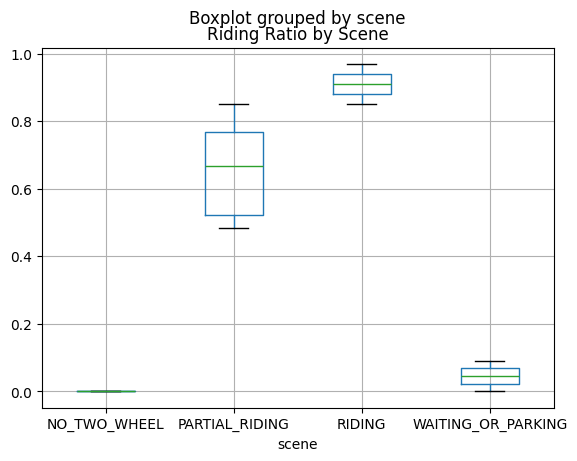

In [51]:
import matplotlib.pyplot as plt

df.boxplot(column="riding_ratio", by="scene")
plt.title("Riding Ratio by Scene")
plt.show()


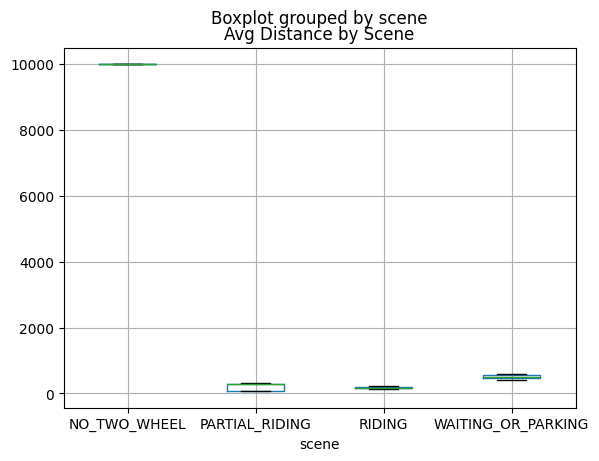

In [52]:
df.boxplot(column="avg_distance", by="scene")
plt.title("Avg Distance by Scene")
plt.show()

In [53]:
risk_flags = {
    "no_helmet": False,        # 아직 detect 못함 → default
    "sidewalk_riding": False   # 아직 detect 못함 → default
}

semantic_tags = []

# 기존 label 기반 mapping
if label == "RIDING":
    semantic_tags.append("riding")

elif label == "PARTIAL_RIDING":
    semantic_tags.append("unstable_riding")

elif label == "WAITING_OR_PARKING":
    semantic_tags.append("stationary")

elif label == "NO_TWO_WHEEL":
    semantic_tags.append("no_vehicle")

In [54]:
result = {
    "scene": label,
    "feature": feature,
    "semantic_tags": semantic_tags,
    "risk_flags": risk_flags
}



In [55]:
def extract_safety_features(data):
    """
    헬멧 + 인도주행 관련 feature 추가
    """

    objects = data.get("objects", [])

    person_count = 0
    helmet_count = 0

    sidewalk_frames = 0
    vehicle_frames = len(data.get("frames", []))

    for obj in objects:
        cls = obj.get("class")

        if cls == "person":
            person_count += 1

        if cls in ["helmet", "head_helmet", "helmet_on"]:
            helmet_count += 1

        # 🚨 인도주행 proxy (bounding box 위치 기반)
        bbox = obj.get("bbox", None)
        if bbox:
            x1, y1, x2, y2 = bbox

            # 화면 하단 or side 영역이면 sidewalk 가능성
            if y2 > 0.8 * 1080:   # (영상 높이 기준)
                sidewalk_frames += 1

    helmet_ratio = helmet_count / max(person_count, 1)
    sidewalk_ratio = sidewalk_frames / max(vehicle_frames, 1)

    return {
        "helmet_ratio": helmet_ratio,
        "sidewalk_ratio": sidewalk_ratio,
        "person_count": person_count,
        "helmet_count": helmet_count
    }

In [56]:
all_features = {}

for file_name in os.listdir(CF2_DIR):

    if not file_name.endswith(".json"):
        continue

    with open(os.path.join(CF2_DIR, file_name), encoding="utf-8") as f:
        data = json.load(f)

    # 기존 feature
    feature = analyze_video(data)

    # 🔥 추가 feature (핵심)
    safety_feature = extract_safety_features(data)

    # 기존 label
    label = classify_scene(feature)

    all_features[file_name] = {
        "scene": label,
        "feature": feature,

        # 🔥 추가
        "safety_feature": safety_feature
    }

    print(file_name, label, safety_feature)

bs_e4387_c1.json PARTIAL_RIDING {'helmet_ratio': 0.0, 'sidewalk_ratio': 0.0, 'person_count': 0, 'helmet_count': 0}
bs_e4387_c2.json PARTIAL_RIDING {'helmet_ratio': 0.0, 'sidewalk_ratio': 0.0, 'person_count': 0, 'helmet_count': 0}
es_e3768_c1.json PARTIAL_RIDING {'helmet_ratio': 0.0, 'sidewalk_ratio': 0.0, 'person_count': 0, 'helmet_count': 0}
es_e3768_c2.json PARTIAL_RIDING {'helmet_ratio': 0.0, 'sidewalk_ratio': 0.0, 'person_count': 0, 'helmet_count': 0}
md_e2122_c1.json PARTIAL_RIDING {'helmet_ratio': 0.0, 'sidewalk_ratio': 0.0, 'person_count': 0, 'helmet_count': 0}
md_e2122_c2.json WAITING_OR_PARKING {'helmet_ratio': 0.0, 'sidewalk_ratio': 0.0, 'person_count': 0, 'helmet_count': 0}
mp_e2730_c1.json RIDING {'helmet_ratio': 0.0, 'sidewalk_ratio': 0.0, 'person_count': 0, 'helmet_count': 0}
mp_e2730_c2.json RIDING {'helmet_ratio': 0.0, 'sidewalk_ratio': 0.0, 'person_count': 0, 'helmet_count': 0}
ms_e3500_c1.json NO_TWO_WHEEL {'helmet_ratio': 0.0, 'sidewalk_ratio': 0.0, 'person_count': 0

In [57]:
def classify_scene(feature, safety_feature=None):

    riding_ratio = feature.get("riding_ratio", 0)

    helmet_ratio = 1
    sidewalk_ratio = 0

    if safety_feature:
        helmet_ratio = safety_feature["helmet_ratio"]
        sidewalk_ratio = safety_feature["sidewalk_ratio"]

    # 기존 logic
    if riding_ratio > 0.8:
        base = "RIDING"
    elif riding_ratio > 0.4:
        base = "PARTIAL_RIDING"
    else:
        base = "WAITING_OR_PARKING"

    # 🔥 추가 rule (핵심)
    violations = []

    if helmet_ratio < 0.5:
        violations.append("NO_HELMET")

    if sidewalk_ratio > 0.3:
        violations.append("SIDEWALK_RIDING")

    if len(violations) == 0:
        return base
    else:
        return base + "_VIOLATION_" + "+".join(violations)

In [58]:
import os
import json
from collections import Counter

CF2_DIR = "./cf2"

counter = Counter()

for file_name in os.listdir(CF2_DIR):
    if not file_name.endswith(".json"):
        continue

    with open(os.path.join(CF2_DIR, file_name), encoding="utf-8") as f:
        data = json.load(f)

    for frame in data["frames"]:
        for cls, cnt in frame["classes"].items():
            counter[cls] += cnt

print(counter)

AttributeError: 'list' object has no attribute 'items'